In [ ]:
!pip install 'qiskit>=2.1.0' 'qiskit-aer>=0.17.0' 'numpy' 'pandas' 'pylatexenc'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 80.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 88.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 73.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.4/54.4 kB 3.6 MB/s eta 0:00:00
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=c8159e7e7804b5bc35237252e4b8594ba5f3b8ce9351e1d8b33fe7d9463830bb
  Stored in directory: /root/.cache/pip/wheels/06/3e/78/fa1588c1ae991bbfd814af2bcac6cef7a178beee1939180d46
Successfully built pylatexenc


# **АЛГОРИТМ ШОРА**

Алгоритм Шора, разработанный Питером Шором в 1994 году, является новаторским квантовым алгоритмом для разложения целых чисел на множители за полиномиальное время. Его значимость заключается в его способности множить большие целые числа экспоненциально быстрее, чем любой известный классический алгоритм, что угрожает безопасности широко используемых криптографических систем, таких как RSA, которые полагаются на сложность разложения на множители больших чисел. Эффективно решив эту проблему на достаточно мощном квантовом компьютере, алгоритм Шора может произвести революцию в таких областях, как криптография, кибербезопасность и вычислительная математика, подчеркнув преобразующую силу квантовых вычислений.

Эта лабораторная работа посвящена демонстрации алгоритма Шора путем разложения на множители числа 15 на квантовом компьютере.

Сначала мы определяем задачу определения порядка и создаем соответствующие схемы из протокола квантовой фазовой оценки. Затем мы запускаем схемы определения порядка, используя схемы с наименьшей глубиной, которые мы можем транслировать. Последний раздел завершает алгоритм Шора, связывая задачу определения порядка с целочисленной факторизацией.

Мы завершаем эту лабораторную работу обсуждением других демонстраций алгоритма Шора на реальном оборудовании, уделяя особое внимание как общим реализациям, так и тем, которые предназначены для разложения на множители конкретных целых чисел, таких как 15 и 21.

In [ ]:
import numpy as np
import pandas as pd
from fractions import Fraction
from math import floor, gcd, log

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import QFT, UnitaryGate
from qiskit.transpiler import CouplingMap, generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

## Шаг 1: Сопоставьте классические входные данные с квантовой задачей

### Справочная информация

Алгоритм Шора для разложения целых чисел на множители использует промежуточную задачу, известную как *задача определения порядка*. В этом разделе мы демонстрируем, как решить задачу определения порядка с помощью *квантовой оценки фазы*.

### Задача оценки фазы
В задаче оценки фазы нам дается квантовое состояние $n$ кубитов, а также единая квантовая схема, которая воздействует на $n$ кубитов. Гарантировано, что $|ψ⟩$ является собственным вектором унитарной матрицы $U$, описывающей работу схемы, и наша цель – вычислить или аппроксимировать собственное значение $λ=e^{2πiθ}$, которому $|ψ⟩$ соответствует. Другими словами, схема должна выдавать приближение к числу $θ∈[0,1)$, удовлетворяющему $U|ψ⟩=e^{2πiθ}|ψ⟩$.  Цель схемы оценки фазы – приблизить $θ$ в $m$ битах. Математически говоря, мы хотели бы найти $y$ таким образом, чтобы $θ≈y/2m$, где $y∈0,1,2,...,2m−1$. На следующем рисунке показана квантовая схема, которая оценивает $y$ в $m$ битах, производя измерения на $m$ кубитах.

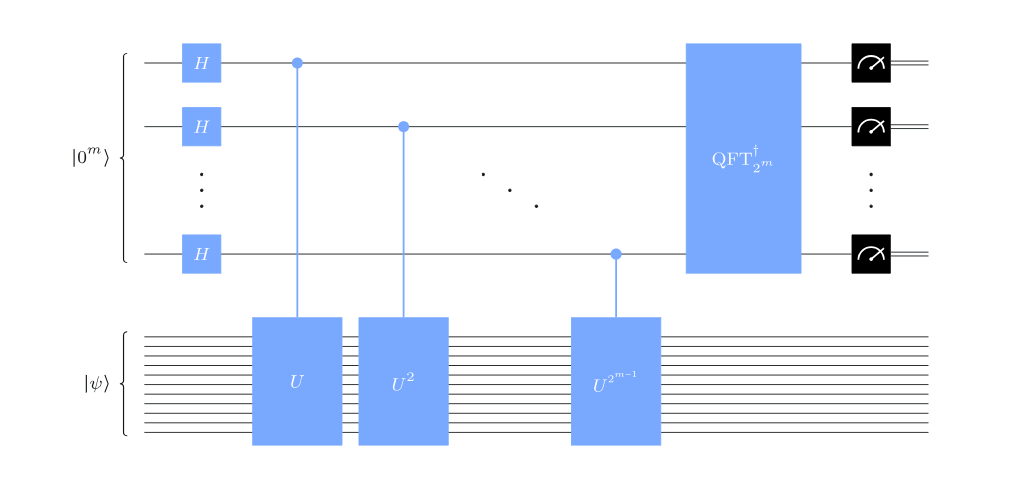

In [ ]:
from IPython.display import Image, display
Image('quantum_phase_estimation.png', width="700")

В приведенной выше схеме верхние $m$ кубитов инициализируются состоянием $|{0^m}\rangle$, а нижние $n$ кубиов инициализируются состоянием $|ψ\rangle$, которое, как было гарантировано, будет собственным вектором $U$. Первым компонентом схемы оценки фазы являются управляемые унитарные операции, которые отвечают за выполнение "обратной связи по фазе" с соответствующим управляющим кубитом. Эти управляемые единицы измерения возводятся в степень в соответствии с положением управляющего кубита в диапазоне от младшего до старшего разряда. Поскольку $|ψ\rangle$ является собственным вектором $U$, эта операция не влияет на состояние нижних $n$ кубитов, но информация о фазе собственного значения распространяется на верхние $m$ кубитов.

Оказывается, что после операции фазового возврата с помощью управляемых унитарных операций все возможные состояния верхних $m$ кубитов ортонормированы друг к другу для каждого собственного вектора $|ψ\rangle$ унитарного $U$. Следовательно, эти состояния прекрасно различимы, и мы можем повернуть базис, который они образуют, обратно к вычислительному базису, чтобы выполнить измерение. Математический анализ показывает, что эта матрица вращения соответствует обратному квантовому преобразованию Фурье (КПФ) в 2-мерном гильбертовом пространстве. Интуитивно это объясняется тем, что периодическая структура операторов модульного возведения в степень закодирована в квантовом состоянии, и КПФ преобразует эту периодичность в измеримые пики в частотной области.

### Задача определения порядка

Чтобы сформулировать задачу определения порядка, мы начнем с некоторых понятий теории чисел. Сначала для любого заданного натурального числа $N$ определим множество $\mathbb{Z}_N$ как $\mathbb{Z}_N = \{0, 1, 2, \dots, N-1\}.$
Все арифметические операции в $\mathbb{Z}_N$ выполняются по модулю $N$. В частности, все элементы $a \in \mathbb {Z}_n$, которые являются взаимно простыми с $N$, являются особыми и составляют $\mathbb {Z}^*_N$ как $\mathbb {Z}^*_N = \{ a \in \mathbb{Z}_N : \mathrm{gcd}(a, N)=1 \}.$
Для элемента $a \ в \mathbb {Z}^*_N$ наименьшее натуральное число $r$, такое, что $a^ r \equiv 1 \; (\mathrm{mod} \; N)$, определяется как *порядок* $a$ по модулю $N$. Как мы увидим позже, определение порядка $a \in \mathbb {Z} ^* _N$ позволит нам разложить $N$ на множители.

Чтобы построить схему определения порядка на основе схемы оценки фазы, нам необходимо соблюсти два условия. Во-первых, нам нужно определить унитарный $U$, который позволит нам найти степень $r$, а во-вторых, нам нужно определить собственный вектор $|ψ\rangle$, равный $U$, чтобы подготовить начальное состояние схемы оценки фазы.

Чтобы связать задачу определения порядка с оценкой фазы, мы рассмотрим операцию, определенную в системе, в которой классические состояния соответствуют  $\mathbb{Z}_N$, где мы умножаем на фиксированный элемент $a \in \mathbb {Z} ^* _N$. В частности, мы определяем этот оператор умножения $M_a$ таким образом, что $M_a |{x}\rangle = |{ax \; (\mathrm {mod} \; N)}\rangle$ для каждого $x \in \mathbb {Z}_N$. Обратите внимание, что подразумевается, что мы берем результат по модулю $N$ в правой части уравнения. Математический анализ показывает, что $M_a$ является унитарным оператором. Кроме того, оказывается, что $M_a$ имеет пары собственных векторов и значений, которые позволяют нам связать степень $r$ числа $a$ с задачей оценки фазы. В частности, для любого выбора из $j \in \{0, \dots, r-1\}$ мы имеем, что $|\psi_j\rangle= \frac{1}{\sqrt{r}} \sum^{r-1}_{k=0} \omega^{-jk}_{r} |{a^k}\rangle$ является собственным вектором $M_a$, соответствующее собственное значение которого равно $\omega^{j}_{r}$, где $\omega^{j}_{r} = e^{2 \pi i \frac{j}{r}}.$

Путем наблюдения мы видим, что удобной парой собственный вектор/собственное значение является состояние $|\psi_1\rangle$ и $\omega^{1}_{r} = e^{2 \pi i \frac{1}{r}}$. Следовательно, если бы мы могли найти собственный вектор $|\psi_1\rangle$, мы могли бы оценить фазу $\theta=1/r$ с помощью нашей квантовой схемы и, следовательно, получить оценку степени $r$. Однако сделать это нелегко, и нам нужно рассмотреть альтернативу.

Давайте рассмотрим, к чему приведет схема, если мы подготовим вычислительное состояние $|1\rangle$ в качестве начального состояния. Это не собственное состояние $M_a$, а равномерная суперпозиция собственных состояний, которые мы только что описали выше. Другими словами, выполняется следующее соотношение: $|1\rangle = \frac{1}{\sqrt{r}} \sum^{r-1}_{k=0}|\psi_k\rangle$
Из приведенного выше уравнения следует, что если мы установим начальное состояние равным $|1\rangle$, мы получим точно такой же результат измерения, как если бы мы выбрали $k \in \{ 0, \dots, r-1\}$ равномерно случайным образом и использовали $|\psi_k\rangle$ в качестве собственного вектора в схеме оценки фазы. Другими словами, измерение верхних $m$ кубитов дает приближение $y / 2^m$ к значению $k / r$, где $k \in \{ 0, \dots, r-1\}$ выбирается равномерно случайным образом. Это позволяет нам узнать $r$ с высокой степенью уверенности после нескольких независимых прогонов, что и было нашей целью.

### Операторы модульного возведения в степень

До сих пор мы связывали задачу оценки фазы с задачей определения порядка, определяя $U = M_a$ и $|\psi\rangle = |1\rangle$ в нашей квантовой схеме. Следовательно, последний оставшийся этап – найти эффективный способ определения модульных показателей $M_a$ как $M_a ^ k$ для $k = 1, 2, 4, \dots, 2^{m-1}$.
Чтобы выполнить это вычисление, мы обнаруживаем, что для любой выбранной нами мощности $k$ мы можем создать схему для $M_a ^ k$, не повторяя $k$ раз схему для $M_a$, а вместо этого вычисляя $b = a^k \; \mathrm{mod} \; N$, а затем используя схему для $M_b$. Поскольку нам нужны только те степени, которые сами по себе являются степенями 2, мы можем сделать это классически эффективно, используя итеративное возведение в квадрат.

## Шаг 2: Оптимизация задачи для выполнения на квантовом оборудовании

### Конкретный пример с $N = 15$ и $a =2$

Здесь мы можем остановиться, чтобы обсудить конкретный пример и построить схему поиска степени для $N=15$. Обратите внимание, что возможные нетривиальные $a \in \mathbb{Z}_N^*$ для $N =15$ равны $a \in \{2, 4, 7, 8, 11, 13, 14 \}$. Для этого примера мы выбираем $a=2$. Мы построим оператор $M_2$ и операторы модульного возведения в степень $M_2^k$.

Воздействие $M_2$ на состояния вычислительного базиса заключается в следующем.

$M_2 |0\rangle = |0\rangle \quad M_2 |5\rangle = |10\rangle \quad M_2 |10\rangle = |5\rangle$

$M_2 |1\rangle = |2\rangle \quad M_2 |6\rangle = |12\rangle \quad M_2 |11\rangle = |7\rangle$

$M_2 |2\rangle = |4\rangle \quad M_2 |7\rangle = |14\rangle \quad M_2 |12\rangle = |9\rangle$

$M_2 |3\rangle = |6\rangle \quad M_2 |8\rangle = |1\rangle \quad M_2 |13\rangle = |11\rangle$

$M_2 |4\rangle = |8\rangle \quad M_2 |9\rangle = |3\rangle \quad M_2 |14\rangle = |13\rangle$

Путем наблюдения мы можем видеть, что базовые состояния перемешиваются, поэтому у нас есть матрица перестановок. Мы можем построить эту операцию на четырех кубитах с помощью вентилей замены. Ниже мы построим операции $M_2$ и управляемые-$M_2$.

In [ ]:
def M2mod15():
    """
    M2 (mod 15)
    """
    b = 2
    U = QuantumCircuit(4)

    U.swap(2, 3)
    U.swap(1, 2)
    U.swap(0, 1)

    U = U.to_gate()
    U.name = f"M_{b}"

    return U

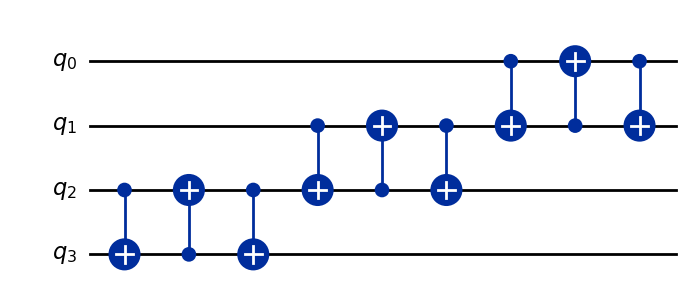

In [ ]:
# Получение оператора M2
M2 = M2mod15()

# Добавьте его в схему и постройте график
circ = QuantumCircuit(4)
circ.compose(M2, inplace=True)
circ.decompose(reps=2).draw(output="mpl", fold=-1)

In [ ]:
def controlled_M2mod15():
    """
    Контролируемый M2 (mod 15)
    """
    b = 2
    U = QuantumCircuit(4)

    U.swap(2, 3)
    U.swap(1, 2)
    U.swap(0, 1)

    U = U.to_gate()
    U.name = f"M_{b}"
    c_U = U.control()

    return c_U

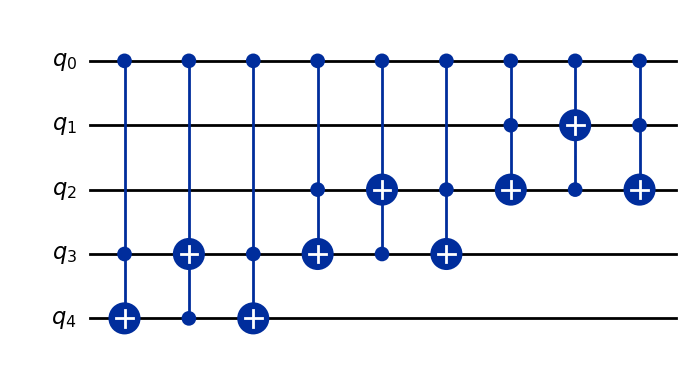

In [ ]:
# Получение контролируемого оператора M2
controlled_M2 = controlled_M2mod15()

# Добавьте его в схему и постройте график
circ = QuantumCircuit(5)
circ.compose(controlled_M2, inplace=True)
circ.decompose(reps=1).draw(output="mpl", fold=-1)

Вентили, действующие более чем на два кубита, будут далее разделены на двухкубитные вентили.

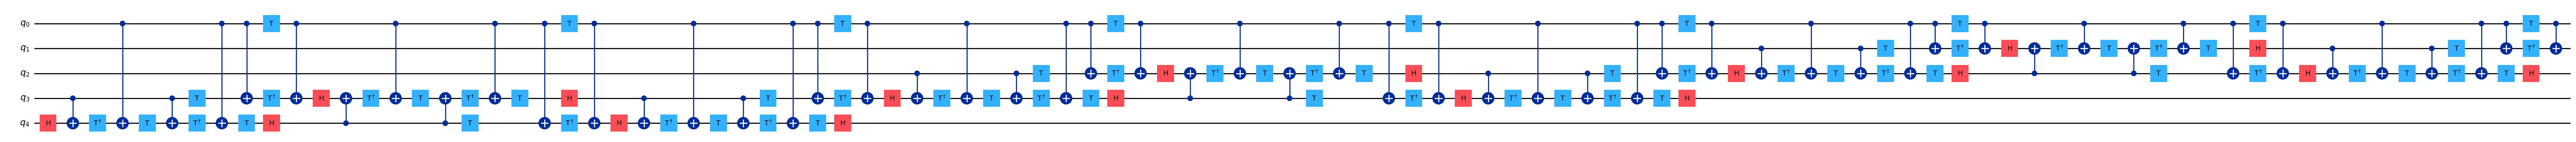

In [ ]:
circ.decompose(reps=2).draw(output="mpl", fold=-1)

Теперь нам нужно построить операторы модульного возведения в степень. Чтобы получить достаточную точность при оценке фазы, мы будем использовать восемь кубитов для измерения. Следовательно, нам нужно построить $M_b$ с $b = a ^{2^k} \; (\mathrm{mod} \; N)$ для каждого $k = 0, 1, \dots, 7$.

In [ ]:
def a2kmodN(a, k, N):
    """Вычислите a ^{2^ k} (по модулю N) путем повторного возведения в квадрат"""
    for _ in range(k):
        a = int(np.mod(a**2, N))
    return a

In [ ]:
k_list = range(8)
b_list = [a2kmodN(2, k, 15) for k in k_list]

print(b_list)

[2, 4, 1, 1, 1, 1, 1, 1]


Как мы можем видеть из списка значений $b$, в дополнение к $M_2$, которое мы создали ранее, нам также нужно создать $M_4$ и $M_1$. Обратите внимание, что $M_1$ тривиально воздействует на состояния вычислительного базиса, поэтому это просто оператор идентификации.

$M_4$ воздействует на состояния вычислительного базиса следующим образом:
$M_4 |0\rangle= |0\rangle \quad M_4 |5\rangle = |5\rangle \quad M_4 |10\rangle = |10\rangle$
$M_4 |1\rangle = |4\rangle \quad M_4 |6\rangle = |9\rangle \quad M_4 |11\rangle = |14\rangle$
$M_4 |2\rangle = |8\rangle \quad M_4 |7\rangle = |13\rangle \quad M_4 |12\rangle = |3\rangle$
$M_4 |3\rangle = |12\rangle \quad M_4 |8\rangle = |2\rangle \quad M_4 |13\rangle = |7\rangle$
$M_4 |4\rangle = |1\rangle \quad M_4 |9\rangle = |6\rangle \quad M_4 |14\rangle = |11\rangle$

Следовательно, эта перестановка может быть сконструирована с помощью следующей операции обмена.



In [ ]:
def M4mod15():
    """
    M4 (mod 15)
    """
    b = 4
    U = QuantumCircuit(4)

    U.swap(1, 3)
    U.swap(0, 2)

    U = U.to_gate()
    U.name = f"M_{b}"

    return U

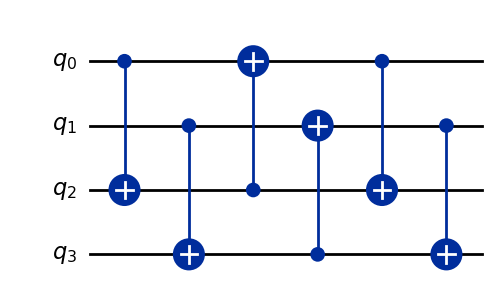

In [ ]:
# Получение оператора M4
M4 = M4mod15()

# Добавьте его в схему и постройте график
circ = QuantumCircuit(4)
circ.compose(M4, inplace=True)
circ.decompose(reps=2).draw(output="mpl", fold=-1)

In [ ]:
def controlled_M4mod15():
    """
    Контролируемый M4 (mod 15)
    """
    b = 4
    U = QuantumCircuit(4)

    U.swap(1, 3)
    U.swap(0, 2)

    U = U.to_gate()
    U.name = f"M_{b}"
    c_U = U.control()

    return c_U

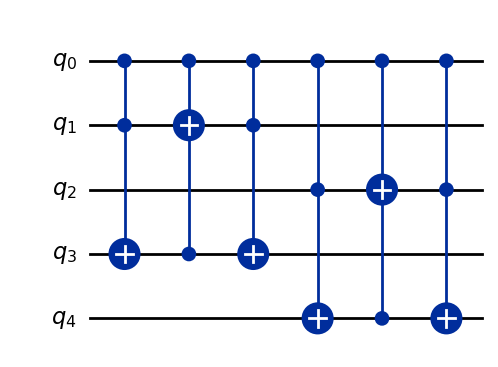

In [ ]:
# Получение контролируемого оператора M4
controlled_M4 = controlled_M4mod15()

# Добавьте его в схему и постройте график
circ = QuantumCircuit(5)
circ.compose(controlled_M4, inplace=True)
circ.decompose(reps=1).draw(output="mpl", fold=-1)

Вентили, действующие более чем на два кубита, будут далее разделены на двухкубитные вентили.

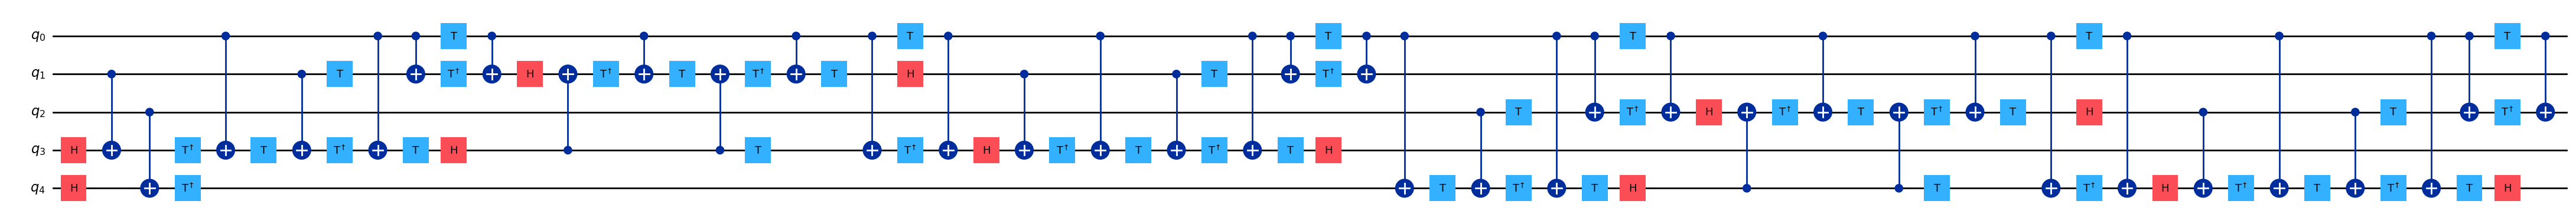

In [ ]:
circ.decompose(reps=2).draw(output="mpl", fold=-1)

Мы видели, что операторы $M_b$ для данного $b \in \mathbb {Z} ^*_N$ являются операциями перестановки. Из-за относительно небольшого размера задачи перестановки, с которой мы сталкиваемся, поскольку для $N = 15$ требуется всего четыре кубита, мы смогли синтезировать эти операции непосредственно с помощью элементов *обмена* путем проверки. В целом, это может оказаться нецелесообразным подходом. Вместо этого нам, возможно, потребуется явно создать матрицу перестановок и использовать класс `UnitaryGate` Qiskit и методы транспиляции для синтеза этой матрицы перестановок. Однако это может привести к значительно более глубоким схемам. Ниже приведен пример.

In [ ]:
def mod_mult_gate(b, N):
    """
    Модульный элемент умножения из матрицы перестановок.
    """
    if gcd(b, N) > 1:
        print(f"Ошибка: НОД({b},{N}) > 1")
    else:
        n = floor(log(N - 1, 2)) + 1
        U = np.full((2**n, 2**n), 0)
        for x in range(N):
            U[b * x % N][x] = 1
        for x in range(N, 2**n):
            U[x][x] = 1
        G = UnitaryGate(U)
        G.name = f"M_{b}"
        return G

кубитов: 4
2q-глубина: 106
2q-размер: 112
Количество операторов: OrderedDict({'cx': 54, 'swap': 42, 'u': 38, 'u2': 7, 'circuit-443': 1, 'circuit-446': 1, 'circuit-449': 1, 'circuit-452': 1, 'circuit-455': 1, 'circuit-458': 1, 'circuit-461': 1, 'circuit-464': 1, 'circuit-467': 1, 'circuit-470': 1, 'circuit-473': 1, 'circuit-476': 1, 'circuit-479': 1, 'circuit-482': 1, 'circuit-485': 1, 'circuit-488': 1})




In [ ]:
# Давайте построим M2, используя определение матрицы перестановок
M2_other = mod_mult_gate(2, 15)

# Добавим его в схему
circ = QuantumCircuit(4)
circ.compose(M2_other, inplace=True)
circ = circ.decompose()

# Преобразуем схему и получим глубину
coupling_map = CouplingMap.from_line(4)
pm = generate_preset_pass_manager(coupling_map=coupling_map)
transpiled_circ = pm.run(circ)

print(f"кубитов: {circ.num_qubits}")
print(
    f"2q-глубина: {transpiled_circ.depth(lambda x: x.operation.num_qubits==2)}"
)
print(f"2q-размер: {transpiled_circ.size(lambda x: x.operation.num_qubits==2)}")
print(f"Количество операторов: {transpiled_circ.count_ops()}")
transpiled_circ.decompose().draw(
    output="mpl", fold=-1, style="clifford", idle_wires=False
)

Давайте сравним эти значения с глубиной скомпилированной схемы нашей ручной реализации вентиля $M_2$.

кубитов: 4
2q-глубина: 9
2q-размер: 9
Количество операторов: OrderedDict({'cx': 9})


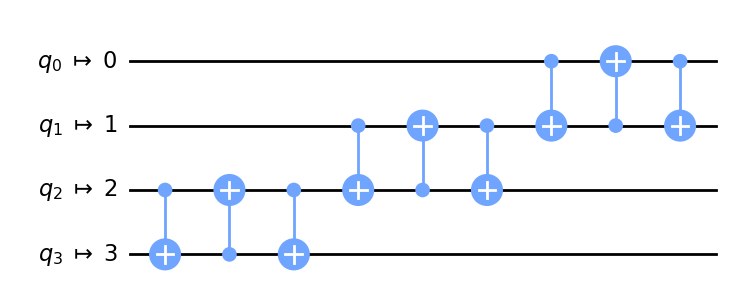

In [ ]:
# Воспользуйтесь оператором M2 из реализации вручную
M2 = M2mod15()

# Добавьте его в схему
circ = QuantumCircuit(4)
circ.compose(M2, inplace=True)
circ = circ.decompose(reps=3)

# Преобразуйте схему и получите глубину
coupling_map = CouplingMap.from_line(4)
pm = generate_preset_pass_manager(coupling_map=coupling_map)
transpiled_circ = pm.run(circ)

print(f"кубитов: {circ.num_qubits}")
print(
    f"2q-глубина: {transpiled_circ.depth(lambda x: x.operation.num_qubits==2)}"
)
print(f"2q-размер: {transpiled_circ.size(lambda x: x.operation.num_qubits==2)}")
print(f"Количество операторов: {transpiled_circ.count_ops()}")
transpiled_circ.draw(
    output="mpl", fold=-1, style="clifford", idle_wires=False
)

Как мы можем видеть, подход с использованием матрицы перестановок привел к значительно более глубокой схеме даже для одного элемента $M_2$ по сравнению с нашей ручной реализацией. Поэтому мы продолжим нашу предыдущую реализацию операций $M_b$.

Теперь мы готовы построить схему определения полного порядка, используя наши ранее определенные управляемые операторы модульного возведения в степень. В следующем коде мы также импортируем схему QFT из библиотеки схем Qiskit, которая использует элементы Адамара на каждом кубите, серию управляемых элементов-$U_1$ (или $Z$, в зависимости от фазы) и слой элементов обмена.

/tmp/ipython-input-2886028578.py:39: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  circuit.compose(QFT(num_control, inverse=True), qubits=control, inplace=True)


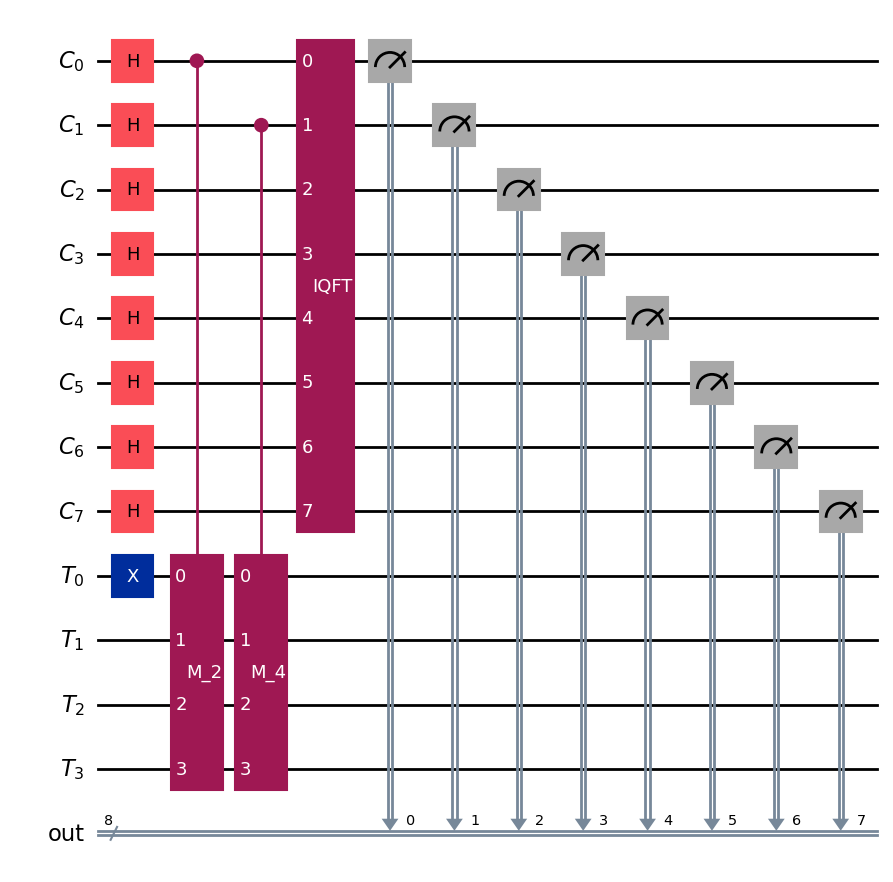

In [ ]:
# Задача нахождения степени для N = 15 и a = 2
N = 15
a = 2

# Количество кубитов
num_target = floor(log(N - 1, 2)) + 1  # для операторов модульного возведения в степень
num_control = 2 * num_target  # для обеспечения достаточной точности оценки

# Список операторов M_b по порядку
k_list = range(num_control)
b_list = [a2kmodN(2, k, 15) for k in k_list]

# Инициализация схемы
control = QuantumRegister(num_control, name="C")
target = QuantumRegister(num_target, name="T")
output = ClassicalRegister(num_control, name="out")
circuit = QuantumCircuit(control, target, output)

# Инициализация целевого регистра состоянием |1>
circuit.x(num_control)

# Добавим элементы Адамара и управляемые версии
# вентилей умножения
for k, qubit in enumerate(control):
    circuit.h(k)
    b = b_list[k]
    if b == 2:
        circuit.compose(
            M2mod15().control(), qubits=[qubit] + list(target), inplace=True
        )
    elif b == 4:
        circuit.compose(
            M4mod15().control(), qubits=[qubit] + list(target), inplace=True
        )
    else:
        continue  # M1 - это оператор идентификации

# Примените обратный QFT к управляющему регистру
circuit.compose(QFT(num_control, inverse=True), qubits=control, inplace=True)

# Измерьте контрольный регистр
circuit.measure(control, output)

circuit.draw("mpl", fold=-1)

Обратите внимание, что мы опустили операции управляемого модульного возведения в степень из оставшихся управляющих кубитов, поскольку $M_1$ является оператором идентификации.

Обратите внимание, что позже в этом руководстве мы запустим эту схему на серверной части 'ibm_marrakesh'. Для этого мы преобразуем схему в соответствии с этой конкретной серверной частью и сообщим о глубине схемы и количестве элементов.

In [ ]:
# Используем локальный симулятор
backend = AerSimulator()

# Транспиляция для симулятора
pm = generate_preset_pass_manager(optimization_level=2, backend=backend)
transpiled_circuit = pm.run(circuit)

print(f"2q-глубина: {transpiled_circuit.depth(lambda x: x.operation.num_qubits==2)}")
print(f"2q-размер: {transpiled_circuit.size(lambda x: x.operation.num_qubits==2)}")
print(f"Количество операторов: {transpiled_circuit.count_ops()}")

2q-глубина: 13
2q-размер: 28
Количество операторов: OrderedDict({'cp': 28, 'ccx': 15, 'h': 14, 'measure': 8, 'x': 1})


## Шаг 3: Выполнение с использованием примитивов Qiskit

Сначала мы обсудим, что мы теоретически получили бы, если бы запустили эту схему на идеальном симуляторе. Ниже мы приводим набор результатов моделирования вышеуказанной схемы с использованием 1024 итераций. Как мы можем видеть, мы получаем приблизительно равномерное распределение по четырем битовым цепочкам по управляющим кубитам.

In [ ]:
# Получено из симулятора
counts = {"00000000": 264, "01000000": 268, "10000000": 249, "11000000": 243}

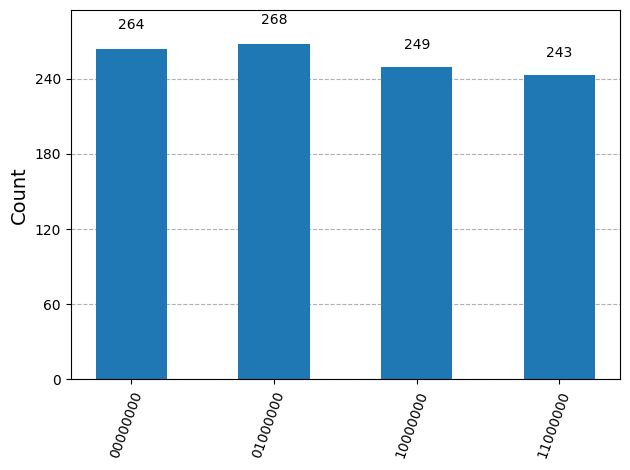

In [ ]:
plot_histogram(counts)

Измеряя управляющие кубиты, мы получаем восьмиразрядную оценку фазы оператора $M_a$. Мы можем преобразовать это двоичное представление в десятичное, чтобы найти измеренную фазу. Как мы можем видеть из приведенной выше гистограммы, были измерены четыре различные последовательности битов, и каждая из них соответствует значению фазы следующим образом.

In [ ]:
# Строки, которые будут отображаться в таблице
rows = []
# Соответствующая фаза каждой битовой строки
measured_phases = []

for output in counts:
    decimal = int(output, 2)  # Преобразовать битовую строку в десятичную
    phase = decimal / (2**num_control)  # Найдите соответствующее собственное значение
    measured_phases.append(phase)
    # Добавьте эти значения в строки нашей таблицы:
    rows.append(
        [
            f"{output}(bin) = {decimal:>3}(dec)",
            f"{decimal}/{2 ** num_control} = {phase:.2f}",
        ]
    )

# Вывести строки таблицей
headers = ["Выход регистра", "Фаза"]
df = pd.DataFrame(rows, columns=headers)
print(df)

             Выход регистра            Фаза
0  00000000(bin) =   0(dec)    0/256 = 0.00
1  01000000(bin) =  64(dec)   64/256 = 0.25
2  10000000(bin) = 128(dec)  128/256 = 0.50
3  11000000(bin) = 192(dec)  192/256 = 0.75


Напомним, что любая измеренная фаза соответствует $\theta = k / r$, где $k$ выбирается равномерно случайным образом из $\{0, 1, \dots, r-1 \}$. Таким образом, мы можем использовать алгоритм непрерывных дробей, чтобы попытаться найти $k$ и степень $r$. В Python встроена эта функциональность. Мы можем использовать модуль fractions для преобразования числа с плавающей точкой в объект Fraction, например:

In [ ]:
Fraction(0.666)

Fraction(5998794703657501, 9007199254740992)

Поскольку это дает дроби, которые возвращают точный результат (в данном случае "0.6660000..."), это может привести к более округленным результатам, подобным приведенному выше. Мы можем использовать метод `.limit_denominator()`, чтобы получить дробь, наиболее похожую на наше число с плавающей точкой, со знаменателем ниже определенного значения:

In [ ]:
# Найдите дробь, наиболее похожую на 0,666
# со знаменателем < 15
Fraction(0.666).limit_denominator(15)

Fraction(2, 3)

Степень (r) должна быть меньше, чем N, поэтому мы установим максимальный знаменатель равным `15`:

In [ ]:
# Строки, которые будут отображаться в таблице
rows = []

for phase in measured_phases:
    frac = Fraction(phase).limit_denominator(15)
    rows.append(
        [phase, f"{frac.numerator}/{frac.denominator}", frac.denominator]
    )

# Вывести строки таблицей
headers = ["Фаза", "Дробь", "Предполагаемое значение r"]
df = pd.DataFrame(rows, columns=headers)
print(df)

   Фаза Дробь  Предполагаемое значение r
0  0.00   0/1                          1
1  0.25   1/4                          4
2  0.50   1/2                          2
3  0.75   3/4                          4


Мы видим, что два из измеренных собственных значений дали нам правильный результат: $r =4$, и мы видим, что алгоритм Шора для определения порядка имеет вероятность сбоя. Эти плохие результаты объясняются тем, что $k = 0$, или тем, что $k$ и $r$ не являются взаимно простыми - и вместо $r$ нам дается множитель $r$. Самое простое решение этой проблемы - просто повторять эксперимент до тех пор, пока мы не получим удовлетворительный результат для $r$.

До сих пор мы реализовывали задачу определения степени для $N = 15$ при $a =2$, используя схему оценки фазы на симуляторе. Последним шагом алгоритма Шора будет связать задачу определения степени с задачей разложения на множители целых чисел. Эта последняя часть алгоритма является чисто классической и может быть решена на классическом компьютере после получения фазовых измерений с квантового компьютера. Поэтому мы отложим последнюю часть алгоритма до тех пор, пока не продемонстрируем, как мы можем запустить схему определения порядка на реальном оборудовании.

### Запуск

Теперь мы можем запустить схему определения степени, которую мы ранее использовали для `ibm_marrakesh`. Здесь мы переходим к динамической развязке (DD) для подавления ошибок и к вращению затвора для устранения ошибок. DD включает в себя применение последовательностей точно рассчитанных управляющих импульсов к квантовому устройству, эффективно устраняя нежелательные взаимодействия с окружающей средой и декогеренцию. С другой стороны, вращение вентилей рандомизирует определенные квантовые вентили, преобразуя когерентные ошибки в ошибки Паули, которые накапливаются линейно, а не квадратично. Оба метода часто комбинируются для повышения согласованности и точности квантовых вычислений.

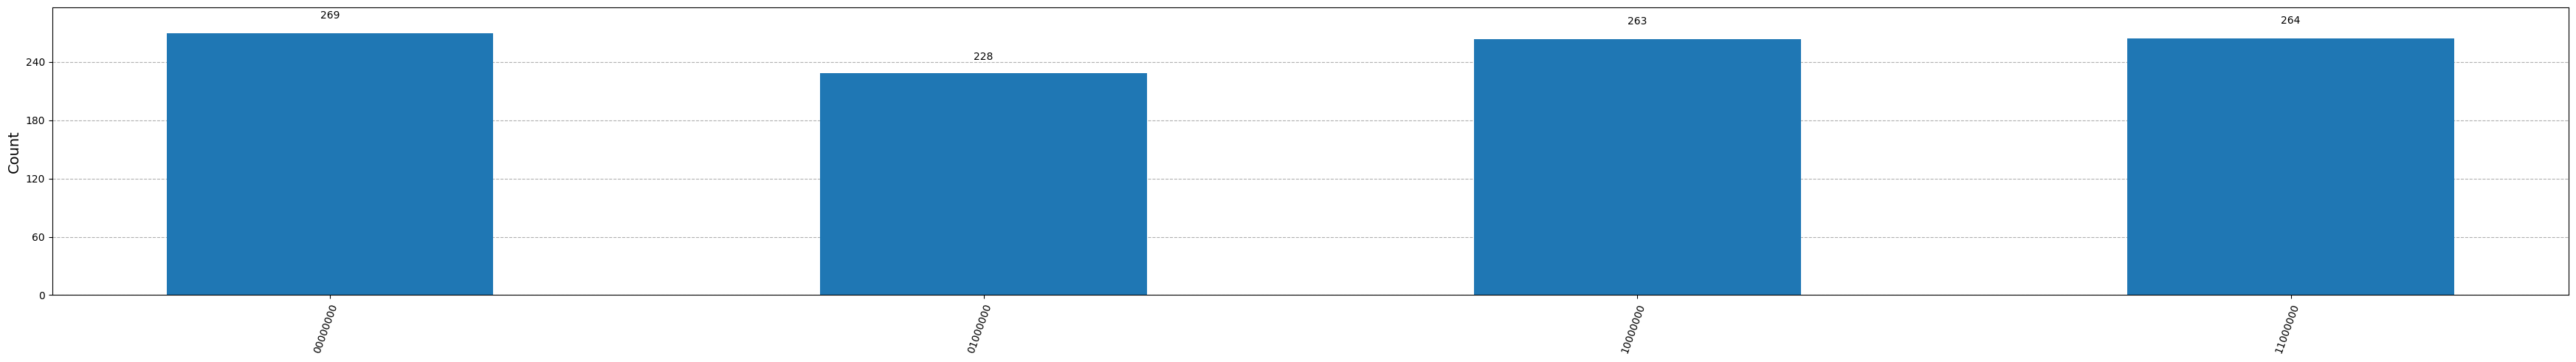

In [ ]:
# Запуск на локальном симуляторе
job = backend.run(transpiled_circuit, shots=1024)
result = job.result()
counts = result.get_counts()

plot_histogram(counts, figsize=(35, 5))

Как мы видим, мы получили одни и те же последовательности битов с наибольшим количеством значений. Поскольку квантовое оборудование имеет помехи, происходит некоторая утечка в другие последовательности битов, которую мы можем отфильтровать статистически.

In [ ]:
# Фильтрация результатов
counts_keep = {}
threshold = np.max(list(counts.values())) / 2

for key, value in counts.items():
    if value > threshold:
        counts_keep[key] = value

print(counts_keep)

{'10000000': 263, '00000000': 269, '01000000': 228, '11000000': 264}


## Шаг 4: Постобработка и возвращение результата в желаемом классическом формате

### Целочисленная факторизация

До сих пор мы обсуждали, как мы можем реализовать задачу определения степени, используя схему оценки фазы. Теперь мы подключаем задачу определения степени к целочисленной факторизации, которая завершает алгоритм Шора. Обратите внимание, что эта часть алгоритма является классической.

Теперь мы продемонстрируем это на нашем примере с $N = 15$ и $a = 2$. Напомним, что измеренная нами фаза равна $k / r$, где $a^r \; (\textrm{mod} \; N) = 1$, а $k$ - случайное целое число в диапазоне от $0$ до $r - 1$. Из этого уравнения мы получаем $(a^ r - 1) \; (\mathrm{mod} \; N) = 0$, что означает, что $N$ должно являться делителем $a^{r-1}$. Если $r$ также четный, то мы можем записать $a^r -1 = (a^{r/2}-1)(a^{r/2}+1)$. Если $r$ нечетный, мы не можем идти дальше и должны повторить попытку с другим значением $a$; в противном случае существует высокая вероятность того, что наибольший общий делитель $N$ и либо $a ^ {r/2}-1$, либо $a ^{r/2} +1$ является правильным множителем $N$.

Поскольку некоторые прогоны алгоритма будут статистически неудачными, мы будем повторять этот алгоритм до тех пор, пока не будет найден хотя бы один коэффициент, равный $N$.

В приведенной ниже ячейке алгоритм повторяется до тех пор, пока не будет найден хотя бы один коэффициент, равный $N=15$. Мы будем использовать результаты аппаратного тестирования, описанные выше, для определения фазы и соответствующего коэффициента на каждой итерации.

In [ ]:
# Постобработка и нахождение множителей
a = 2
N = 15

FACTOR_FOUND = False
num_attempt = 0

while not FACTOR_FOUND and num_attempt < len(counts_keep):
    print(f"\nПопытка {num_attempt}:")
    bitstring = list(counts_keep.keys())[num_attempt]
    num_attempt += 1

    decimal = int(bitstring, 2)
    phase = decimal / (2**num_control)
    print(f"Фаза: theta = {phase}")

    frac = Fraction(phase).limit_denominator(N)
    r = frac.denominator
    print(f"Преполагаемое значение степени {a} по модулю {N}: r = {r}")

    if phase != 0 and r % 2 == 0:
        x = pow(a, r // 2, N) - 1
        d = gcd(x, N)
        if d > 1 and d < N:
            FACTOR_FOUND = True
            print(f"*** Найденный нетривиальный множитель: {d} ***")
            print(f"Множители {N}: {d} и {N // d}")


Попытка 0:
Фаза: theta = 0.5
Преполагаемое значение степени 2 по модулю 15: r = 2

Попытка 1:
Фаза: theta = 0.0
Преполагаемое значение степени 2 по модулю 15: r = 1

Попытка 2:
Фаза: theta = 0.25
Преполагаемое значение степени 2 по модулю 15: r = 4
*** Найденный нетривиальный множитель: 3 ***
Множители 15: 3 и 5


## Задание

Задание для каждого варианта:
1. Проверьте условие взаимной простоты: убедитесь, что $gcd(a, N) = 1$.
2. Определите количество кубитов: рассчитайте необходимое количество кубитов для регистров управления и цели.
3. Постройте схему определения порядка: реализуйте операторы модульного умножения $M_a$ и их степени.
4. Выполните схему на симуляторе: запустите схему на локальном симуляторе AerSimulator.
5. Обработайте результаты: из полученных измерений найдите оценку фазы $θ = k/r$.
6. Найдите порядок $r$: используя алгоритм непрерывных дробей, определите порядок $r$.

7. Найдите множители $N$: если $r$ чётное, вычислите:

$\quad \quad x$ = $a^{(r/2)} mod N$

$\quad \quad d_1 = gcd(x - 1, N)$

$\quad \quad d_2 = gcd(x + 1, N)$

Нетривиальные множители $N$: $d_1$ и $d_2$.

|Вариант|N|a|
|--|--|--|
|1|14351|2|
|2|25367|3|
|3|34891|5|
|4|45673|7|
|5|56789|11|
|6|67891|13|
|7|78901|17|
|8|89012|19|
|9|90123|23|
|10|12347|29|
|11|23459|31|
|12|34567|37|
|13|45679|41|
|14|56789|43|
|15|67891|47|
|16|78923|53|
|17|89237|59|
|18|92347|61|
|19|10357|67|
|20|11311|71|
|21|12763|73|
|22|13829|79|
|23|14327|83|
|24|15733|89|
|25|16381|97|
|26|17431|101|
|27|18233|103|
|28|19429|107|
|29|20173|109|
|30|21317|113|